# Human Activity Recognition Using Smartphone Sensors

## ML Zoomcamp 2026 — Midterm Project

### Problem Description

The objective of this project is to classify human physical activities using smartphone sensor data.

We use the UCI Human Activity Recognition (HAR) dataset, which contains 561 pre-extracted features from accelerometer and gyroscope signals.

The target variable represents six activities:

1. Walking
2. Walking Upstairs
3. Walking Downstairs
4. Sitting
5. Standing
6. Laying

This is a multiclass classification problem.

We will train and compare machine learning models, evaluate their performance on unseen participants, and deploy the selected model as a prediction service.

**Dataset:** UCI Human Activity Recognition Using Smartphones

**Source:** https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones

**Evaluation strategy:** The original test set will remain untouched until final evaluation. Training and validation data will be separated by participant to prevent subject leakage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## 1. Data Preparation

### 1.1 Loading the Dataset

We load the original training and test datasets.

The feature matrices contain 561 numerical features extracted from smartphone sensors.

Activity labels and subject identifiers are stored in separate files.

We retain the original train/test partition provided by UCI.

In [2]:
# Training features
X_train = pd.read_csv(
    'data/X_train.txt',
    sep=r'\s+',
    header=None
)

# Training labels
y_train = pd.read_csv('data/y_train.txt', header=None)

# Participant identifiers
subjects_train = pd.read_csv('data/subject_train.txt', header=None)

In [3]:
# Official test features
X_test = pd.read_csv(
    'data/X_test.txt',
    sep=r'\s+',
    header=None
)

# Official test labels
y_test = pd.read_csv('data/y_test.txt', header=None)

# Test participant identifiers
subjects_test = pd.read_csv('data/subject_test.txt', header=None)

In [4]:
print('X_train:', X_train.shape)
print('y_train:', y_train.shape)
print('subjects_train:', subjects_train.shape)

print('X_test:', X_test.shape)
print('y_test:', y_test.shape)
print('subjects_test:', subjects_test.shape)

X_train: (7352, 561)
y_train: (7352, 1)
subjects_train: (7352, 1)
X_test: (2947, 561)
y_test: (2947, 1)
subjects_test: (2947, 1)


## 2. Exploratory Data Analysis (EDA)

We explore the training dataset to understand its structure, data quality, and target distribution.

The analysis includes:

- Dataset dimensions and feature types
- Missing values
- Distribution of the six activity classes
- Number of participants
- Verification of participant separation between training and test sets

The official test set will not be used to make modeling or hyperparameter tuning decisions.

In [5]:
# Display the first five rows and first five feature columns
X_train.iloc[:, :5].head()

,0,1,2,3,4
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817


In [6]:
X_train.dtypes.value_counts()

float64    561
Name: count, dtype: int64

In [7]:
print('Missing values:', X_train.isnull().sum().sum())

Missing values: 0


### 2.1 Target Variable

The target variable contains six activity classes, encoded as integers from 1 to 6.

We examine the number of observations in each class to identify possible class imbalance.

In [8]:
y_train[0].value_counts().sort_index()

0
1    1226
2    1073
3     986
4    1286
5    1374
6    1407
Name: count, dtype: int64

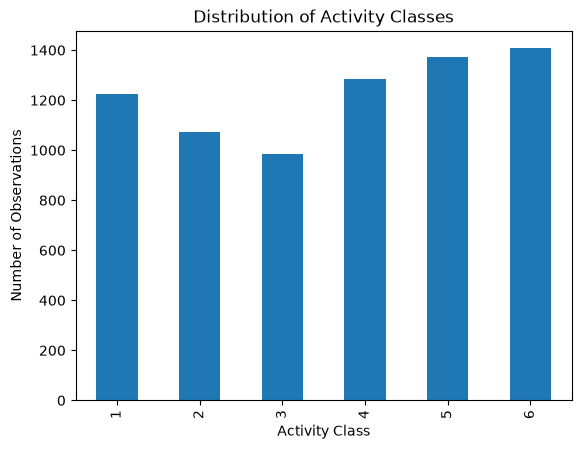

In [9]:
y_train[0].value_counts().sort_index().plot(kind='bar')

plt.xlabel('Activity Class')
plt.ylabel('Number of Observations')
plt.title('Distribution of Activity Classes')
plt.show()

### 2.2 Participant Distribution

The dataset contains measurements from multiple participants.

To evaluate generalization to unseen individuals, we must ensure that participants in the training and validation sets do not overlap.

We first verify the original training/test separation.

In [10]:
print('Training subjects:', subjects_train[0].nunique())
print('Test subjects:', subjects_test[0].nunique())

train_subjects = set(subjects_train[0])
test_subjects = set(subjects_test[0])

print('Subject overlap:', train_subjects & test_subjects)

Training subjects: 21
Test subjects: 9
Subject overlap: set()


### 2.3 EDA Findings

- The training dataset contains 7,352 observations and 561 numerical features.
- All features are stored as float64 values.
- No missing values were detected.
- The six activity classes are relatively balanced.
- The original training and test sets contain 21 and 9 distinct participants, respectively.
- There is no participant overlap between the original training and test sets.

The dataset is ready for model training. We will preserve the official test set for final evaluation.

## 3. Model Training and Evaluation

### 3.1 Train/Validation Split

We create a validation set from the original training participants.

The split is performed at the participant level to ensure that recordings from the same person do not appear in both sets.

The official test set remains untouched until final model evaluation.

We use `random_state=42` for reproducibility.

In [11]:
from sklearn.model_selection import train_test_split

# Keep the original training data for final model training
X_full_train = X_train.copy()
y_full_train = y_train[0].copy()

# Split participant IDs
train_ids, val_ids = train_test_split(
    subjects_train[0].unique(),
    test_size=0.25,
    random_state=42
)

# Select recordings belonging to each group
train_mask = subjects_train[0].isin(train_ids)
val_mask = subjects_train[0].isin(val_ids)

X_train = X_full_train[train_mask].copy()
X_val = X_full_train[val_mask].copy()

y_train = y_full_train[train_mask].values
y_val = y_full_train[val_mask].values

print('X_train:', X_train.shape)
print('X_val:', X_val.shape)

print('Train subjects:', len(train_ids))
print('Validation subjects:', len(val_ids))
print('Subject overlap:', set(train_ids) & set(val_ids))

X_train: (5270, 561)
X_val: (2082, 561)
Train subjects: 15
Validation subjects: 6
Subject overlap: set()


### 3.2 Majority-Class Baseline

We establish a simple baseline that always predicts the most frequent activity in the training set.

We evaluate classification performance using accuracy and macro-averaged F1-score.

In [12]:
from sklearn.metrics import accuracy_score, f1_score

# Find the most frequent training class
majority_class = pd.Series(y_train).mode()[0]

# Predict the majority class for every validation observation
y_pred_baseline = np.repeat(majority_class, len(y_val))

baseline_accuracy = accuracy_score(y_val, y_pred_baseline)
baseline_f1 = f1_score(y_val, y_pred_baseline, average='macro')

print('Baseline Accuracy:', round(baseline_accuracy, 4))
print('Baseline Macro-F1:', round(baseline_f1, 4))

Baseline Accuracy: 0.1849
Baseline Macro-F1: 0.052


### 3.3 Logistic Regression

We train a Logistic Regression classifier as our first machine learning model.

Feature standardization is applied using StandardScaler, fitted only on the training data to prevent data leakage.

We evaluate the model using validation accuracy and macro-F1.

In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# Train Logistic Regression
model = LogisticRegression(max_iter=2000, random_state=42)

model.fit(X_train_scaled, y_train)

# Predict validation labels
y_pred = model.predict(X_val_scaled)

# Evaluate
accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')

print('Validation Accuracy:', round(accuracy, 4))
print('Validation Macro-F1:', round(macro_f1, 4))

Validation Accuracy: 0.9577
Validation Macro-F1: 0.9543


### 3.4 Logistic Regression — Hyperparameter Tuning

We evaluate different values of the regularization parameter C.

The objective is to identify the model with the best validation macro-F1 score while maintaining good generalization to unseen participants.

In [14]:
for C in [0.01, 0.1, 1, 10]:
    model = LogisticRegression(
        C=C,
        max_iter=2000,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_val_scaled)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average='macro')

    print('C=%s Accuracy=%.4f Macro-F1=%.4f' %
          (C, accuracy, macro_f1))

C=0.01 Accuracy=0.9510 Macro-F1=0.9449
C=0.1 Accuracy=0.9553 Macro-F1=0.9510
C=1 Accuracy=0.9577 Macro-F1=0.9543
C=10 Accuracy=0.9496 Macro-F1=0.9465


**Logistic Regression — Findings**

- Four regularization strengths were evaluated.
- The best validation macro-F1 was 0.9543 with C=1.
- The corresponding validation accuracy was 0.9577.
- Logistic Regression substantially outperformed the majority-class baseline.
- The model achieved strong performance on unseen validation participants.

We retain C=1 as the best Logistic Regression configuration.

### 3.5 Decision Tree Classification

We train Decision Tree classifiers to capture non-linear relationships between smartphone sensor features and human activities.

We evaluate different max_depth values to investigate the effect of tree complexity on validation performance.

Model selection is based on validation macro-F1.

In [15]:
from sklearn.tree import DecisionTreeClassifier

for depth in [3, 5, 10, 15, None]:
    dt = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    dt.fit(X_train, y_train)

    y_pred = dt.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average='macro')

    print('depth=%s Accuracy=%.4f Macro-F1=%.4f' %
          (depth, accuracy, macro_f1))

depth=3 Accuracy=0.7848 Macro-F1=0.7219
depth=5 Accuracy=0.8429 Macro-F1=0.8349
depth=10 Accuracy=0.8890 Macro-F1=0.8867
depth=15 Accuracy=0.8833 Macro-F1=0.8794
depth=None Accuracy=0.8770 Macro-F1=0.8738


**Decision Tree — Findings**

- Five max_depth values were evaluated.
- The best validation macro-F1 was 0.8867 with max_depth=10.
- Increasing tree depth beyond 10 did not improve validation performance.
- Decision Tree performed worse than Logistic Regression (macro-F1=0.9543).

We proceed to Random Forest to investigate whether combining multiple trees improves classification performance.

### 3.6 Random Forest Classification

We train a Random Forest classifier to investigate whether an ensemble of decision trees improves classification performance.

We evaluate the model on unseen validation participants using accuracy and macro-F1.

In [16]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)

accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')

print('Validation Accuracy:', round(accuracy, 4))
print('Validation Macro-F1:', round(macro_f1, 4))

Validation Accuracy: 0.9275
Validation Macro-F1: 0.9208


**Random Forest — Initial Results**

- The Random Forest with 100 trees achieved a validation accuracy of 0.9275.
- The validation macro-F1 was 0.9208.
- It outperformed the best individual Decision Tree but performed worse than Logistic Regression.

We will tune max_depth to investigate whether controlling tree complexity improves performance.

### 3.7 Random Forest — Hyperparameter Tuning

We evaluate different values of max_depth while keeping n_estimators=100.

Model selection is based on validation macro-F1.

In [17]:
for depth in [10, 20, 30, None]:
    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average='macro')

    print('depth=%s Accuracy=%.4f Macro-F1=%.4f' %
          (depth, accuracy, macro_f1))

depth=10 Accuracy=0.9284 Macro-F1=0.9208
depth=20 Accuracy=0.9308 Macro-F1=0.9246
depth=30 Accuracy=0.9275 Macro-F1=0.9208
depth=None Accuracy=0.9275 Macro-F1=0.9208


**Random Forest — Hyperparameter Tuning Findings**

- Four max_depth values were evaluated with 100 estimators.
- The best validation macro-F1 was 0.9246 with max_depth=20.
- Increasing tree depth beyond 20 did not improve performance.
- Random Forest outperformed the individual Decision Tree but remained below Logistic Regression.

We proceed to XGBoost for the final model comparison.

### 3.8 XGBoost Classification

We train an XGBoost classifier to evaluate whether gradient boosting improves activity recognition performance.

We use the same subject-wise training and validation sets as the previous models.

Performance is evaluated using accuracy and macro-F1.

In [18]:
from xgboost import XGBClassifier

# XGBoost requires class labels starting from 0
y_train_xgb = y_train - 1

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective='multi:softprob',
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train, y_train_xgb)

# Convert predictions back to the original labels (1-6)
y_pred = xgb.predict(X_val) + 1

accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')

print('Validation Accuracy:', round(accuracy, 4))
print('Validation Macro-F1:', round(macro_f1, 4))

Validation Accuracy: 0.951
Validation Macro-F1: 0.9464


**XGBoost — Initial Findings**

- The initial XGBoost model achieved a validation accuracy of 0.9510.
- The validation macro-F1 was 0.9464.
- XGBoost outperformed Decision Tree and Random Forest.
- Logistic Regression remained the best-performing model.

We evaluate different max_depth values before final model selection.

### 3.9 XGBoost — Hyperparameter Tuning

We evaluate different max_depth values while keeping n_estimators=100 and learning_rate=0.1.

The models are compared using validation macro-F1.

In [19]:
for depth in [2, 3, 5]:
    xgb = XGBClassifier(
        n_estimators=100,
        max_depth=depth,
        learning_rate=0.1,
        objective='multi:softprob',
        random_state=42,
        n_jobs=-1
    )

    xgb.fit(X_train, y_train_xgb)

    y_pred = xgb.predict(X_val) + 1

    accuracy = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average='macro')

    print('depth=%s Accuracy=%.4f Macro-F1=%.4f' %
          (depth, accuracy, macro_f1))

depth=2 Accuracy=0.9524 Macro-F1=0.9477
depth=3 Accuracy=0.9510 Macro-F1=0.9464
depth=5 Accuracy=0.9433 Macro-F1=0.9394


**XGBoost — Hyperparameter Tuning Findings**

- Three max_depth values were evaluated.
- The best validation macro-F1 was 0.9477 with max_depth=2.
- Increasing max_depth did not improve performance.
- XGBoost performed well but did not outperform Logistic Regression.

We select Logistic Regression as the best-performing model based on validation macro-F1.

### 3.10 Best Model — Detailed Evaluation

Logistic Regression with C=1 achieved the highest validation macro-F1.

We examine the classification report and confusion matrix to evaluate performance across the six activity classes.

                    precision    recall  f1-score   support

           Walking       0.96      0.99      0.98       386
  Walking Upstairs       0.90      1.00      0.95       317
Walking Downstairs       1.00      0.83      0.91       280
           Sitting       0.91      0.98      0.95       339
          Standing       0.98      0.93      0.95       375
            Laying       1.00      0.99      1.00       385

          accuracy                           0.96      2082
         macro avg       0.96      0.95      0.95      2082
      weighted avg       0.96      0.96      0.96      2082



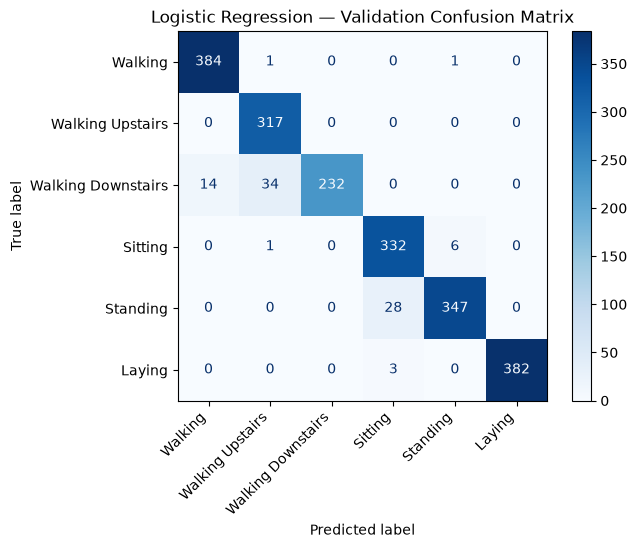

In [20]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Train the selected Logistic Regression model
best_model = LogisticRegression(
    C=1,
    max_iter=2000,
    random_state=42
)

best_model.fit(X_train_scaled, y_train)

# Validation predictions
y_pred = best_model.predict(X_val_scaled)

activity_names = [
    'Walking',
    'Walking Upstairs',
    'Walking Downstairs',
    'Sitting',
    'Standing',
    'Laying'
]

# Classification report
print(classification_report(
    y_val,
    y_pred,
    target_names=activity_names
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred,
    display_labels=activity_names,
    cmap='Blues'
)

plt.xticks(rotation=45, ha='right')
plt.title('Logistic Regression — Validation Confusion Matrix')
plt.show()

**Logistic Regression — Detailed Evaluation Findings**

- The selected model achieved a validation accuracy of 0.9577 and macro-F1 of 0.9543.
- Walking Upstairs and Laying were classified with particularly high recall.
- Walking Downstairs was the most challenging activity, with a recall of 0.83.
- The main classification errors occurred between Walking Downstairs and other walking activities, and between Sitting and Standing.
- Overall, the model demonstrated strong performance on six unseen validation participants.

Logistic Regression with C=1 was selected for final evaluation.

## 4. Final Model Evaluation

### 4.1 Training on the Full Training Dataset

We retrain the selected Logistic Regression model using all 7,352 original training observations.

The StandardScaler is fitted exclusively on the full training dataset.

The final model is evaluated on the official UCI HAR test set, containing nine unseen participants.

In [21]:
# Standardize the full training dataset
final_scaler = StandardScaler()

X_full_train_scaled = final_scaler.fit_transform(X_full_train)
X_test_scaled = final_scaler.transform(X_test)

# Train the selected model
final_model = LogisticRegression(
    C=1,
    max_iter=2000,
    random_state=42
)

final_model.fit(X_full_train_scaled, y_full_train)

# Evaluate on the official test set
y_test_pred = final_model.predict(X_test_scaled)

test_accuracy = accuracy_score(y_test[0], y_test_pred)
test_macro_f1 = f1_score(y_test[0], y_test_pred, average='macro')

print('Test Accuracy:', round(test_accuracy, 4))
print('Test Macro-F1:', round(test_macro_f1, 4))

Test Accuracy: 0.9555
Test Macro-F1: 0.9554


### 4.2 Final Evaluation Findings

The selected Logistic Regression model (C=1) was retrained on the full original training dataset of 7,352 observations.

The model was evaluated on the official UCI HAR test set containing nine unseen participants.

**Final results:**
- Test Accuracy: 0.9555
- Test Macro-F1: 0.9554

The test results were consistent with validation performance, suggesting good generalization to unseen participants under the dataset's experimental conditions.

The model will now be exported for deployment.